In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/bank-full[1].csv', sep=';')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 rows:")
display(df.head())

First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (45211, 17)


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
print("Target variable distribution:")
print(df['y'].value_counts())

print("\nTarget variable percentage:")
print(df['y'].value_counts(normalize=True) * 100)

Target variable distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target variable percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [10]:
print("Number of duplicate records:")
print(df.duplicated().sum())

Number of duplicate records:
0


In [11]:
print("Numerical columns:")
print(df.select_dtypes(include=['int64', 'float64']).columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include=['object']).columns.tolist())


Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


In [12]:
for column in df.select_dtypes(include=['object']).columns:
    print("\n", column)
    print(df[column].unique())


 job
['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']

 marital
['married' 'single' 'divorced']

 education
['tertiary' 'secondary' 'unknown' 'primary']

 default
['no' 'yes']

 housing
['yes' 'no']

 loan
['no' 'yes']

 contact
['unknown' 'cellular' 'telephone']

 month
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

 poutcome
['unknown' 'failure' 'other' 'success']

 y
['no' 'yes']


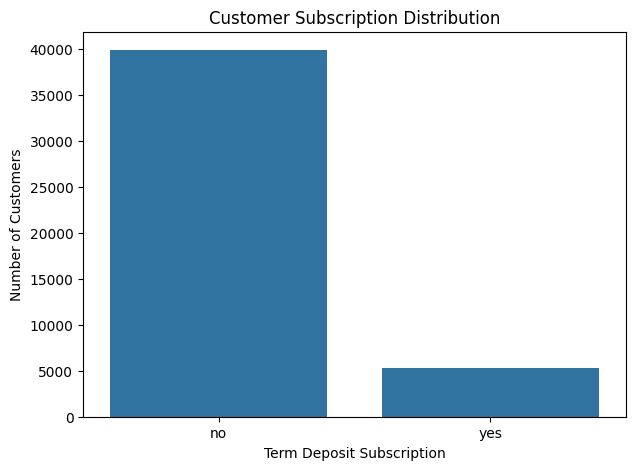

In [13]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='y')

plt.title('Customer Subscription Distribution')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()

The graph shows that the number of customers who did not subscribe to the bank's term deposit is much higher than the number of customers who subscribed.

This indicates that only a smaller proportion of customers responded positively to the bank's marketing campaign, while most customers were not interested in subscribing.

**Business Interpretation:**

This suggests that the bank's marketing campaign is not equally successful with all customers. The bank needs to identify customers who are more likely to subscribe so that it can focus its marketing efforts on the right audience.

**Key Finding:** The dataset has an imbalance between customers who subscribed and those who did not. This is important to consider while building the machine learning model.

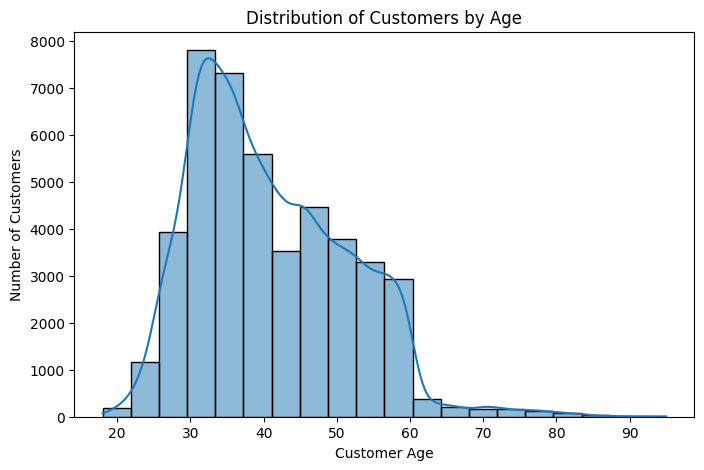

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='age', bins=20, kde=True)

plt.title('Distribution of Customers by Age')
plt.xlabel('Customer Age')
plt.ylabel('Number of Customers')

plt.show()

The graph shows the age distribution of customers who participated in the bank's marketing campaign. Most customers are between 30 and 40 years old. The highest number of customers can be seen around the age group of 30–35 years.

The graph also shows that the number of customers gradually decreases as age increases beyond 40. Very few customers are above 60 years old.

**Business Interpretation:**

The bank's marketing campaign has a larger representation of customers in the 30–40 age group. Understanding the age distribution can help the bank study customer behaviour and plan marketing campaigns for different age groups.

**Key Finding:** Most customers in the dataset belong to the 30–40 age group, while older customers are represented in smaller numbers.

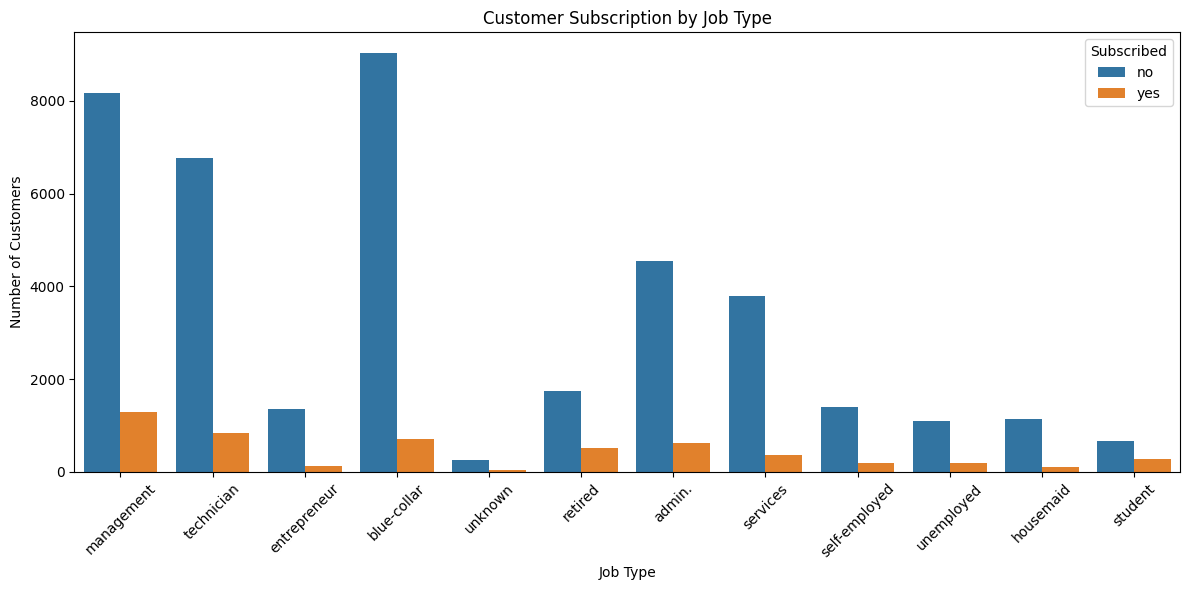

In [15]:
plt.figure(figsize=(12,6))

sns.countplot(data=df, x='job', hue='y')

plt.title('Customer Subscription by Job Type')
plt.xlabel('Job Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

The graph shows the number of customers who subscribed and did not subscribe to the bank's term deposit across different job categories.

It can be observed that customers working in management, technician and blue-collar jobs form a larger part of the dataset. However, the number of customers who did not subscribe is higher than those who subscribed across all job categories.

The graph also shows that customers from different occupations participated in the marketing campaign, but their responses were not the same.

**Business Interpretation:**

The bank can use customers' occupation details to understand different customer groups and plan suitable marketing campaigns. Instead of following the same marketing strategy for everyone, the bank can study the response patterns of different occupational groups.

**Key Finding:** Management, technician and blue-collar workers have higher customer representation in the dataset. Non-subscriptions are higher than subscriptions across all job categories.

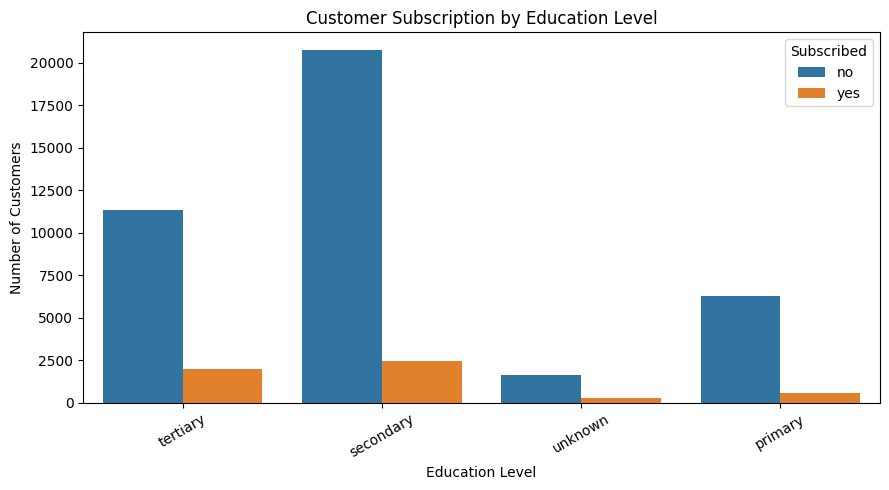

In [19]:
plt.figure(figsize=(9,5))

sns.countplot(data=df, x='education', hue='y')

plt.title('Customer Subscription by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.xticks(rotation=30)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

The graph shows the number of customers who subscribed and did not subscribe to the bank's term deposit based on their education levels.

It can be observed that customers with secondary education form the largest group, followed by customers with tertiary education. Customers with primary education and unknown education levels are fewer in comparison.

The graph also shows that the number of customers who did not subscribe is higher than those who subscribed across all education categories.

**Business Interpretation:**

The bank can use customers' education details to understand different customer groups and plan suitable marketing strategies. This information may help the marketing team develop better ways to communicate with customers from different educational backgrounds.

**Key Finding:** Customers with secondary education have the highest representation in the dataset, while non-subscriptions are higher across all education categories.

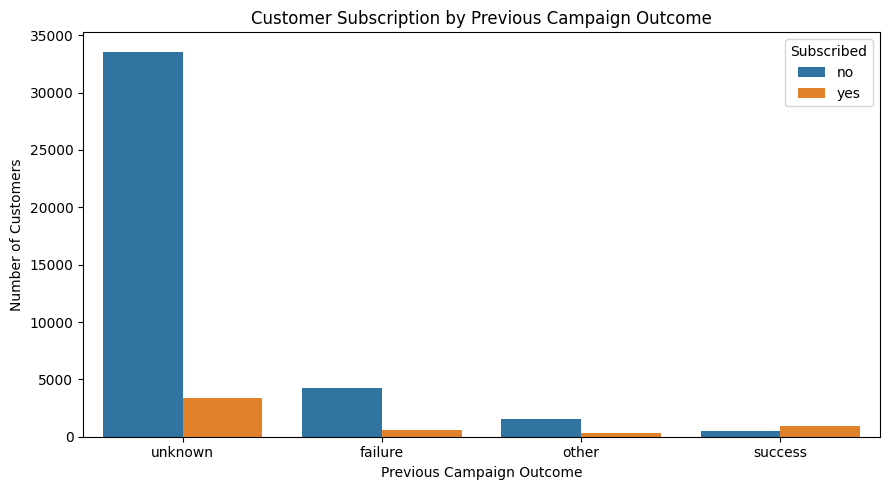

In [20]:
plt.figure(figsize=(9,5))

sns.countplot(data=df, x='poutcome', hue='y')

plt.title('Customer Subscription by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

The graph shows the relationship between the outcome of a customer's previous marketing campaign and their current subscription decision.

It can be observed that most customers have an unknown previous campaign outcome, meaning there is no recorded outcome available for their previous campaign. Among customers whose previous campaign was successful, the number of customers who subscribed is higher than those who did not subscribe.

However, customers whose previous campaign failed have more non-subscriptions than subscriptions.

**Business Interpretation:**
The bank can use information about previous campaign results to identify customers who may be more interested in its financial products. Customers who responded positively to earlier campaigns could be considered for future marketing activities.

**Key Finding:** Previous campaign success appears to be associated with a higher number of current subscriptions. This information can help the bank improve its customer targeting strategy.

In [21]:
# Separate input variables and target variable

X = df.drop(['y', 'duration'], axis=1)
y = df['y']

print("Input variables shape:", X.shape)
print("Target variable shape:", y.shape)

Input variables shape: (45211, 15)
Target variable shape: (45211,)


In [22]:
print("Independent Variables:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Independent Variables:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  campaign  pdays  previous poutcome  
0  unknown    5   may         1     -1         0  unknown  
1  unknown    5   may         1     -1         0  unknown  
2  unknown    5   may         1     -1         0  unknown  
3  unknown    5   may         1     -1         0  unknown  
4  unknown    5   may         1     -1         0  unknown  

Target Variable:
0    no
1    no
2    no
3    no
4    no
Name: y, dtype: object


In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36168, 15)
Testing data: (9043, 15)


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [26]:
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

print("Preprocessing system created successfully!")

Preprocessing system created successfully!


In [28]:
print("Preprocessing system:")
print(preprocessor)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

Preprocessing system:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'balance', 'day', 'campaign', 'pdays',
                                  'previous']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'poutcome'])])

Training records: 36168
Testing records: 9043


In [29]:
print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

print("\nPreprocessing system:")
print(preprocessor)

Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing system:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'balance', 'day', 'campaign', 'pdays',
                                  'previous']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'poutcome'])])


In [30]:
from sklearn.linear_model import LogisticRegression

In [31]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [33]:
# Predict using Logistic Regression

y_pred_lr = logistic_model.predict(X_test)

print("Predictions generated successfully!")
print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10])

Predictions generated successfully!

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no']


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("LOGISTIC REGRESSION MODEL PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred_lr, pos_label='yes'))
print("F1 Score:", f1_score(y_test, y_pred_lr, pos_label='yes'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION MODEL PERFORMANCE
Accuracy: 0.7548379962401858
Precision: 0.2662363856393707
Recall: 0.6238185255198487
F1 Score: 0.37319762510602206

Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.62      0.37      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043



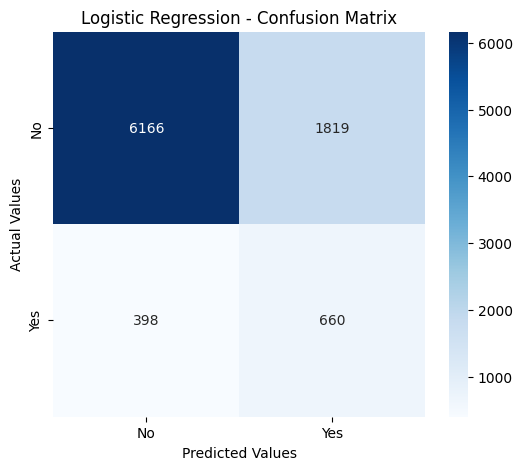

In [35]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr, labels=['no', 'yes'])

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

The Logistic Regression model achieved an accuracy of 75.48%. Its precision for the positive class (Yes) was 26.62%, while its recall was 62.38%. The F1-score was 37.32%.

The model was able to identify approximately 62% of customers who actually subscribed to the bank's term deposit. However, its precision was relatively low, indicating that many customers predicted as potential subscribers did not actually subscribe.

This suggests that the model can identify a reasonable proportion of potential subscribers, but its predictions still include a considerable number of incorrect positive predictions.

**Business Interpretation:**

The bank can use the model to identify potential customers for marketing campaigns. However, the low precision means the bank should not rely entirely on these predictions when allocating its marketing budget. Further model improvement is required.

In [38]:
from sklearn.ensemble import RandomForestClassifier

In [39]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [40]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [41]:
# Generate predictions using Random Forest

y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("RANDOM FOREST MODEL PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred_rf, pos_label='yes'))
print("F1 Score:", f1_score(y_test, y_pred_rf, pos_label='yes'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST MODEL PERFORMANCE
Accuracy: 0.8932876257879022
Precision: 0.6302521008403361
Recall: 0.21266540642722118
F1 Score: 0.31802120141342755

Classification Report:
              precision    recall  f1-score   support

          no       0.90      0.98      0.94      7985
         yes       0.63      0.21      0.32      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.60      0.63      9043
weighted avg       0.87      0.89      0.87      9043



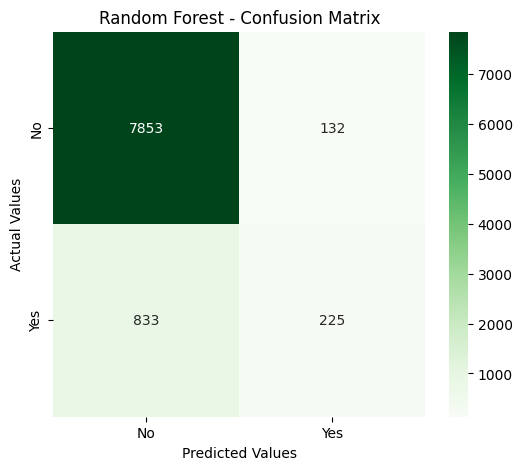

In [43]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=['no', 'yes'])

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

The Random Forest model achieved an accuracy of 89.38%. Its precision for the positive class (Yes) was 63.03%, while its recall was 21.27%. The F1-score was 31.80%.

The model correctly identified a large number of customers who did not subscribe. However, it identified only a small proportion of actual subscribers. The confusion matrix shows that 833 actual subscribers were incorrectly classified as non-subscribers.

**Business Interpretation:**

Although Random Forest achieved higher overall accuracy, its ability to identify potential subscribers was limited. This could result in the bank missing many customers who may be interested in its term deposit.

## Step 15: Comparison of Machine Learning Models

Two machine learning algorithms, Logistic Regression and Random Forest, were compared using accuracy, precision, recall and F1-score.

| Evaluation Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 75.48% | 89.38% |
| Precision | 26.62% | 63.03% |
| Recall | 62.38% | 21.27% |
| F1-score | 37.32% | 31.80% |

**Understanding the Comparison:**

Random Forest achieved higher accuracy and precision than Logistic Regression. However, Logistic Regression performed better in recall and F1-score.

Since our project focuses on identifying customers who are likely to subscribe to the bank's term deposit, identifying actual subscribers is important.

Therefore, Logistic Regression is the provisional preferred model because it identifies a larger proportion of actual subscribers.

**Business Interpretation:**

The bank should consider a model that can identify more potential subscribers rather than focusing only on overall accuracy. This can help the marketing team reduce missed opportunities and improve customer targeting.

In [44]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, pos_label='yes'),
        precision_score(y_test, y_pred_rf, pos_label='yes')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, pos_label='yes'),
        recall_score(y_test, y_pred_rf, pos_label='yes')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, pos_label='yes'),
        f1_score(y_test, y_pred_rf, pos_label='yes')
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7548,0.2662,0.6238,0.3732
1,Random Forest,0.8933,0.6303,0.2127,0.3180


In [45]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
import numpy as np

# Divide training data into training and validation sets

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Sub-training data:", X_subtrain.shape)
print("Validation data:", X_val.shape)

Sub-training data: (28934, 15)
Validation data: (7234, 15)


In [46]:
# Create a separate Logistic Regression model

tuned_lr = clone(logistic_model)

# Train using sub-training data

tuned_lr.fit(X_subtrain, y_subtrain)

# Get subscription probabilities on validation data

val_probabilities = tuned_lr.predict_proba(X_val)[:, 1]

# Calculate precision and recall at different thresholds

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities,
    pos_label='yes'
)

# Calculate F1 scores

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find threshold with highest validation F1-score

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", round(best_threshold, 4))
print("Validation Precision:", round(precision[best_index], 4))
print("Validation Recall:", round(recall[best_index], 4))
print("Validation F1 Score:", round(f1_scores[best_index], 4))

Best threshold: 0.6635
Validation Precision: 0.483
Validation Recall: 0.4208
Validation F1 Score: 0.4498


In [47]:
from sklearn.metrics import classification_report

# Retrain using the complete training dataset

final_lr = clone(logistic_model)
final_lr.fit(X_train, y_train)

# Predict probabilities on unseen test data

test_probabilities = final_lr.predict_proba(X_test)[:, 1]

# Apply the selected threshold

y_pred_tuned = np.where(
    test_probabilities >= best_threshold,
    'yes',
    'no'
)

print("IMPROVED LOGISTIC REGRESSION PERFORMANCE")

print(classification_report(
    y_test,
    y_pred_tuned,
    labels=['no', 'yes']
))

IMPROVED LOGISTIC REGRESSION PERFORMANCE
              precision    recall  f1-score   support

          no       0.92      0.94      0.93      7985
         yes       0.48      0.42      0.45      1058

    accuracy                           0.88      9043
   macro avg       0.70      0.68      0.69      9043
weighted avg       0.87      0.88      0.88      9043



### Step 16: Model Improvement Using Threshold Tuning

Threshold tuning was performed to improve the performance of the Logistic Regression model. Initially, the model used a default probability threshold of 0.50. After evaluating different thresholds on the validation dataset, a threshold of 0.6635 was selected based on the highest validation F1-score.

The improved model achieved approximately 88% accuracy, 48% precision, 42% recall and 45% F1-score for the positive class.

Compared with the original model, precision and F1-score improved, while recall decreased. This means the improved model makes more reliable positive predictions but identifies a smaller proportion of actual subscribers.

**Business Interpretation:**

Threshold tuning helps the bank adjust its customer targeting strategy. The improved model reduces the number of customers incorrectly identified as potential subscribers. However, some interested customers may still be missed. Therefore, the bank must balance the cost of contacting uninterested customers against the opportunity lost by missing potential subscribers.

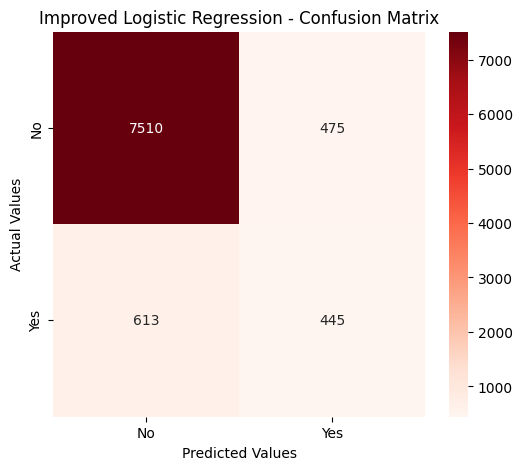

In [49]:
cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=['no', 'yes']
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Improved Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

The confusion matrix shows that the improved Logistic Regression model correctly classified 7,510 non-subscribers and 445 subscribers. However, 475 non-subscribers were incorrectly predicted as subscribers, while 613 actual subscribers were missed by the model.

The model has improved its ability to identify potential subscribers compared with the Random Forest model. However, some actual subscribers are still being missed.

**Business Interpretation:**

The bank can use these predictions to identify customers who may be interested in subscribing to its term deposit. The marketing team should focus on predicted potential subscribers while recognising that the model may not identify every interested customer.

In [50]:
# Extract feature names after preprocessing

feature_names = final_lr.named_steps['preprocessor'].get_feature_names_out()

# Extract Logistic Regression coefficients

coefficients = final_lr.named_steps['classifier'].coef_[0]

# Create a feature importance table

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Absolute Importance': np.abs(coefficients)
})

# Display the 15 most influential features

feature_importance = feature_importance.sort_values(
    by='Absolute Importance',
    ascending=False
)

display(feature_importance.head(15))

,Feature,Coefficient,Absolute Importance
48,cat__poutcome_success,1.677444,1.677444
41,cat__month_mar,1.222427,1.222427
38,cat__month_jan,-1.050970,1.050970
44,cat__month_oct,0.932936,0.932936
36,cat__month_dec,0.849234,0.849234
45,cat__month_sep,0.791316,0.791316
43,cat__month_nov,-0.788269,0.788269
35,cat__month_aug,-0.740694,0.740694
33,cat__contact_unknown,-0.708806,0.708806
46,cat__poutcome_failure,-0.664030,0.664030


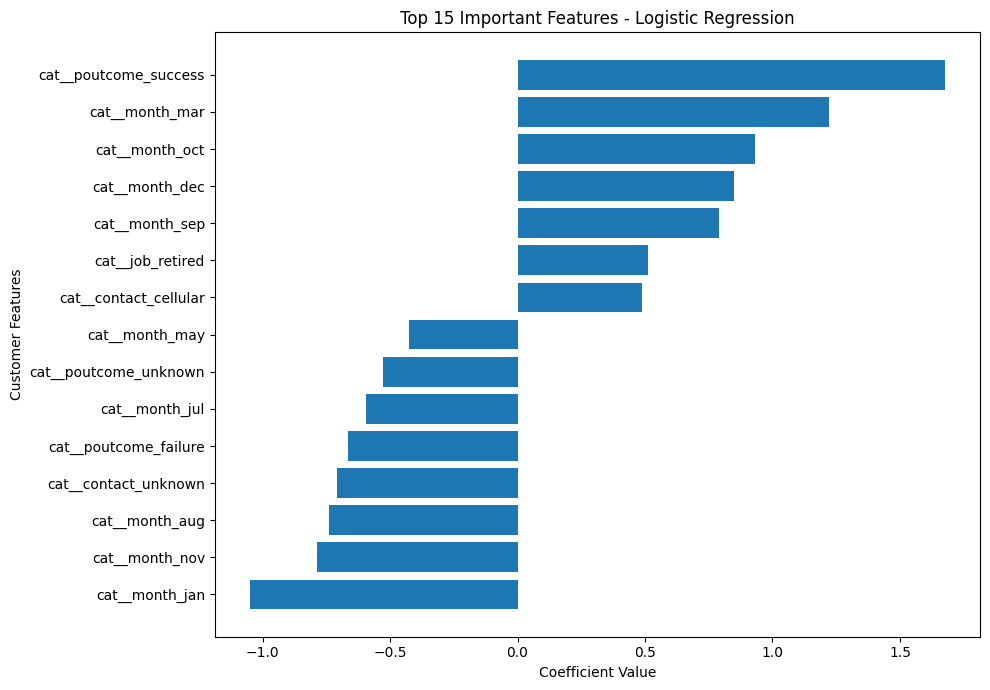

In [51]:
top_features = feature_importance.head(15).sort_values(
    by='Coefficient'
)

plt.figure(figsize=(10,7))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.title('Top 15 Important Features - Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Customer Features')

plt.tight_layout()
plt.show()

Feature importance analysis was performed using the coefficients of the Logistic Regression model to identify the customer characteristics most strongly associated with subscription predictions.

The analysis shows that a previous successful campaign outcome has the strongest positive coefficient. Certain contact months, including March, October, December and September, also have positive coefficients.

On the other hand, January, November and August have negative coefficients. Previous campaign failure and unknown contact information are also negatively associated with subscription predictions.

**Business Interpretation:**

The bank can use previous campaign outcomes as an important factor when planning future marketing activities. Customers who responded positively to earlier campaigns may be suitable for further targeted communication.

The bank can also examine campaign timing and improve the collection of customer contact information. However, these patterns should be validated before making marketing decisions because the model identifies associations rather than causal relationships.

In [52]:
import joblib

In [53]:
joblib.dump(final_lr, 'marketing_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [54]:
joblib.dump(best_threshold, 'best_threshold.pkl')

print("Prediction threshold saved successfully!")

Prediction threshold saved successfully!


In [55]:
import os

print("Saved files:")

for file in os.listdir():
    if file.endswith('.pkl'):
        print(file)

Saved files:
marketing_model.pkl
best_threshold.pkl


In [58]:
import sklearn
print(sklearn.__version__)

1.6.1
